In [26]:
import copy, math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the diabetes dataset
dt = pd.read_csv('diabetes.csv')

# Clean the dataset by removing rows with zero values in BMI, Glucose, Age, and BloodPressure
df_clean = dt[(dt['BMI'] != 0) & (dt['Glucose'] != 0) & (dt['Age'] != 0) & (dt['BloodPressure'] != 0)]   

# Transform the cleaned DataFrame into NumPy arrays for features and target variable
X_train = df_clean[['BMI', 'Age', 'BloodPressure']].to_numpy()
y_train = df_clean['Glucose'].to_numpy()

# Print the shapes and types of the feature and target arrays
print(f"X Shape: {X_train.shape}, X Type:{type(X_train)})")
print(X_train)
print(f"y Shape: {y_train.shape}, y Type:{type(y_train)})")
print(y_train)

X Shape: (724, 3), X Type:<class 'numpy.ndarray'>)
[[33.6 50.  72. ]
 [26.6 31.  66. ]
 [23.3 32.  64. ]
 ...
 [26.2 30.  72. ]
 [30.1 47.  60. ]
 [30.4 23.  70. ]]
y Shape: (724,), y Type:<class 'numpy.ndarray'>)
[148  85 183  89 137 116  78 197 110 168 139 189 166 118 107 103 115 126
  99 196 119 143 125 147  97 145 117 109 158  88  92 122 103 138 102  90
 111 180 133 106 171 159 180 146  71 103 103 101  88 176 150  73 187 100
 146 105 133  44 141 114  99 109 109  95 146 100 139 126 129  79  62  95
 112 113  83 101 137 110 106 100 136 107  80 123  81 134 142 144  92  71
  93 122 163 151 125  81  85 126  96 144  83  95 171 155  89  76 160 146
 124  78  97  99 162 111 107 132 113  88 120 118 117 105 173 122 170  84
  96 125 100  93 129 105 128 106 108 108 154  57 106 147  90 136 114 156
 153 188 152  99 109  88 163 151 102 114 100 131 104 148 120 110 111 102
 134  79  75 179  85 129 143 130  87 119  73 141 194 181 128 109 139 111
 123 159  85 158 105 107 109 148 113 138 108  99 103 111

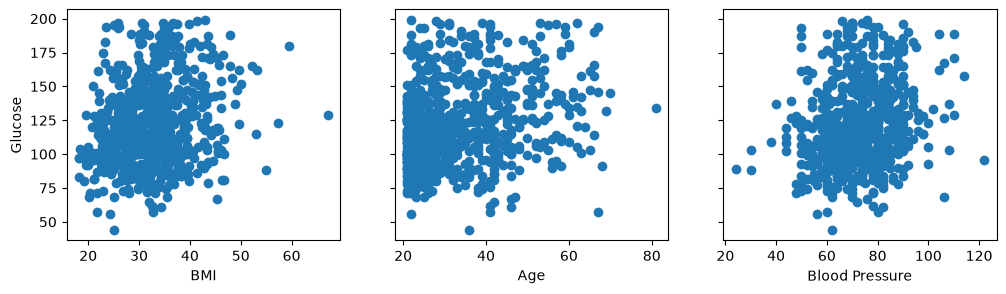

In [20]:
# Plot each feature against the target variable (Glucose)
X_features = ['BMI', 'Age', 'Blood Pressure']

fig,ax=plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for i in range(len(ax)):
    ax[i].scatter(X_train[:,i],y_train)
    ax[i].set_xlabel(X_features[i])
ax[0].set_ylabel("Glucose")
plt.show()

In [21]:
def zscore_normalize_features(X):
    """
    Normalize the features using z-score normalization.
    
    Parameters:
    X (numpy.ndarray): The input feature array.
    
    Returns:
    numpy.ndarray: The normalized feature array.
    """
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    
    X_norm = (X - mean) / std if std.any() else X - mean
    
    return X_norm, mean, std

print("Before normalization:")
print(X_train)

X_train_norm, mean, std = zscore_normalize_features(X_train)

print("After normalization:")
print(X_train_norm)

Before normalization:
[[33.6 50.  72. ]
 [26.6 31.  66. ]
 [23.3 32.  64. ]
 ...
 [26.2 30.  72. ]
 [30.1 47.  60. ]
 [30.4 23.  70. ]]
After normalization:
[[ 0.16456174  1.41607523 -0.03237751]
 [-0.85226209 -0.19994691 -0.51737031]
 [-1.33162189 -0.11489311 -0.67903458]
 ...
 [-0.9103663  -0.28500071 -0.03237751]
 [-0.34385017  1.16091384 -1.00236311]
 [-0.30027201 -0.88037728 -0.19404178]]


In [22]:
def compute_cost(X, y, w, b): 
  """
  compute cost
  Args:
    X (ndarray (m,n)): Data, m examples with n features
    y (ndarray (m,)) : target values
    w (ndarray (n,)) : model parameters  
    b (scalar)       : model parameter
      
  Returns:
    cost (scalar): cost
  """
  m = X.shape[0]
  cost = 0.0
  for i in range(m):                                
      f_wb_i = np.dot(X[i], w) + b        
      cost = cost + (f_wb_i - y[i])**2       
  cost = cost / (2 * m)                         
  return cost

In [40]:
def compute_gradient(X, y, w, b): 
  """
  Computes the gradient for linear regression 
  Args:
    X (ndarray (m,n)): Data, m examples with n features
    y (ndarray (m,)) : target values
    w (ndarray (n,)) : model parameters  
    b (scalar)       : model parameter
      
  Returns:
    dj_db (scalar):       The gradient of the cost w.r.t. the parameter b. 
    dj_dw (ndarray (n,)): The gradient of the cost w.r.t. the parameters w. 
    
  """
  m,n = X.shape          
  dj_dw = np.zeros((n,))
  dj_db = 0.

  for i in range(m):                             
      err = (np.dot(X[i], w) + b) - y[i]   
      for j in range(n):                         
          dj_dw[j] = dj_dw[j] + err * X[i, j]    
      dj_db = dj_db + err                        
  dj_dw = dj_dw / m                                
  dj_db = dj_db / m                                
        
  return dj_db, dj_dw

In [38]:
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters): 
    """
    Performs batch gradient descent to learn w and b. Updates w and b by taking 
    num_iters gradient steps with learning rate alpha
    
    Args:
      X (ndarray (m,n))   : Data, m examples with n features
      y (ndarray (m,))    : target values
      w_in (ndarray (n,)) : initial model parameters  
      b_in (scalar)       : initial model parameter
      cost_function       : function to compute cost
      gradient_function   : function to compute the gradient
      alpha (float)       : Learning rate
      num_iters (int)     : number of iterations to run gradient descent
      
    Returns:
      w (ndarray (n,)) : Updated values of parameters 
      b (scalar)       : Updated value of parameter 
      """
    
    J_history = []
    w = copy.deepcopy(w_in)  
    b = b_in
    
    for i in range(num_iters):

        dj_db,dj_dw = gradient_function(X, y, w, b)   

        w = w - alpha * dj_dw               
        b = b - alpha * dj_db               
      
        if i<100000:     
            J_history.append( cost_function(X, y, w, b))

        if i% math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}, weights: {w}, bias: {b}")
        
    return w, b, J_history 

Iteration    0: Cost  7750.42, weights: [0.06861014 0.08098886 0.06862698], bias: 1.2188259668508288
Iteration  100: Cost  1393.40, weights: [3.90530527 4.64539275 3.23900226], bias: 77.71575418223227
Iteration  200: Cost   544.90, weights: [5.06888483 6.05341142 3.53482032], bias: 105.71610391711847
Iteration  300: Cost   431.22, weights: [5.49409886 6.57130159 3.35461004], bias: 115.96513748704814
Iteration  400: Cost   415.94, weights: [5.68074675 6.79724025 3.17269895], bias: 119.7166152404374
Iteration  500: Cost   413.87, weights: [5.77379773 6.90850013 3.05178255], bias: 121.08977742574488
Iteration  600: Cost   413.59, weights: [5.82344781 6.96714591 2.97954621], bias: 121.59239919538092
Iteration  700: Cost   413.54, weights: [5.85076908 6.99910771 2.93799512], bias: 121.77637501849566
Iteration  800: Cost   413.54, weights: [5.86599545 7.01679722 2.91444608], bias: 121.84371611976805
Iteration  900: Cost   413.54, weights: [5.87452254 7.02665642 2.90117976], bias: 121.8683651

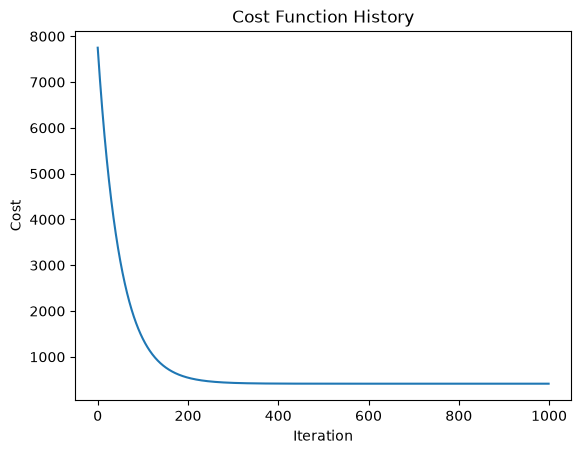

In [43]:
# Initialize parameters for gradient descent
w_init = np.zeros(X_train_norm.shape[1])
b_init = 0.0
alpha = 0.01 # 0.001 was too low, 0.01 worked fine        
num_iters = 1000 # 10000 was too high, moved to 1000

# Run gradient descent
w_final, b_final, J_hist = gradient_descent(X_train_norm, y_train, w_init, b_init, compute_cost, compute_gradient, alpha, num_iters)

# Plot the cost function history to visualize convergence
plt.plot(J_hist)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Cost Function History")
plt.show()

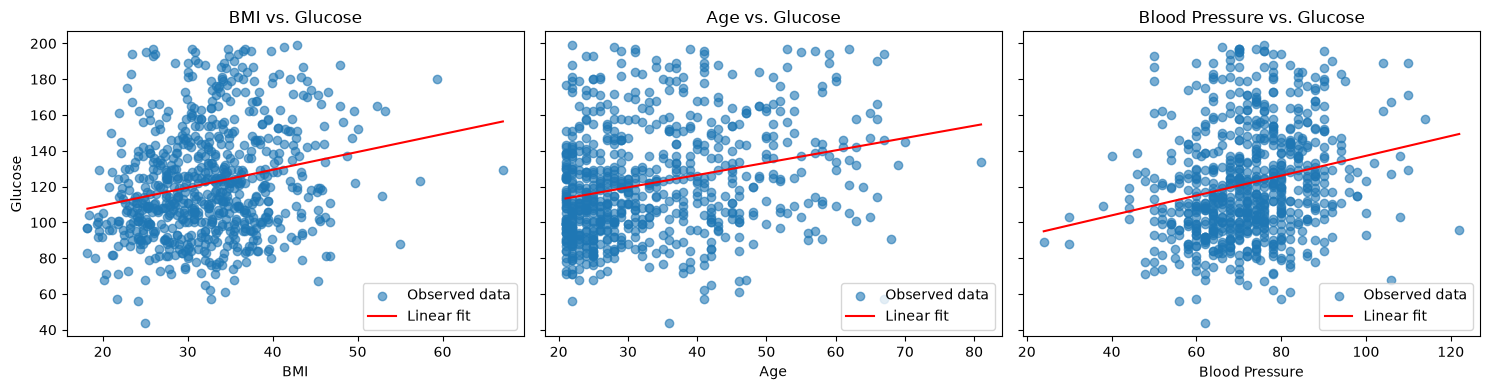

In [45]:
# Cost is high, learning rate isn`t the problem, the model is converging well
# Plot each feature against Glucose with its own univariate least-squares fit to see if the linear function is the problem
fig, ax = plt.subplots(1, len(X_features), figsize=(15, 4), sharey=True)

for i, feature in enumerate(X_features):
    x_feature = X_train[:, i]
    slope, intercept = np.polyfit(x_feature, y_train, 1)
    line_x = np.linspace(x_feature.min(), x_feature.max(), 100)

    ax[i].scatter(x_feature, y_train, alpha=0.6, label="Observed data")
    ax[i].plot(line_x, slope * line_x + intercept, color="red", label="Linear fit")
    ax[i].set_xlabel(feature)
    ax[i].set_title(f"{feature} vs. Glucose")
    ax[i].legend()

ax[0].set_ylabel("Glucose")
plt.tight_layout()
plt.show()

In [53]:
# test inputs to the final model

print(f"final parameters: w = {w_final}, b = {b_final}")

# Testing the model with our previously defined limit of BMI for being candidate for prediabetes, first varying Age and keeping Blood Pressure values the same
x_test = np.array([[27.5, 21, 80], [27.5, 25, 80], [27.5, 30, 80], [27.5, 45, 80], [27.5, 60, 80]])
x_test_norm = (x_test - mean) / std

print("\nPredictions for test inputs (varying Age):")
for i, x in enumerate(x_test_norm):
    prediction = np.dot(x, w_final) + b_final
    print(f"Input: {x_test[i]} -> Predicted Glucose: {prediction:.2f}")

# Testing the model with varying Blood Pressure and keeping Age constant
x_test2 = np.array([[27.5, 25, 60], [27.5, 25, 70], [27.5, 25, 80], [27.5, 25, 90], [27.5, 25, 100]])
x_test2_norm = (x_test2 - mean) / std

print("\nPredictions for test inputs (varying Blood Pressure):")
for i, x in enumerate(x_test2_norm):
    prediction = np.dot(x, w_final) + b_final
    print(f"Input: {x_test2[i]} -> Predicted Glucose: {prediction:.2f}")

# Testing the model to find the age and blood pressure that would result in a predicted glucose level of 100 mg/dL for a BMI of 27.5
x_test3 = np.array([[27.5, 21, 100], [27.5, 25, 90], [27.5, 30, 80], [27.5, 45, 70], [27.5, 60, 60]])
x_test3_norm = (x_test3 - mean) / std

print("\nPredictions for test inputs (varying Age and Blood Pressure):")
for i, x in enumerate(x_test3_norm):
    prediction = np.dot(x, w_final) + b_final
    print(f"Input: {x_test3[i]} -> Predicted Glucose: {prediction:.2f}")

final parameters: w = [5.87927049 7.03212836 2.89377998], b = 121.87733486134633

Predictions for test inputs (varying Age):
Input: [27.5 21.  80. ] -> Predicted Glucose: 112.03
Input: [27.5 25.  80. ] -> Predicted Glucose: 114.42
Input: [27.5 30.  80. ] -> Predicted Glucose: 117.41
Input: [27.5 45.  80. ] -> Predicted Glucose: 126.38
Input: [27.5 60.  80. ] -> Predicted Glucose: 135.35

Predictions for test inputs (varying Blood Pressure):
Input: [27.5 25.  60. ] -> Predicted Glucose: 109.74
Input: [27.5 25.  70. ] -> Predicted Glucose: 112.08
Input: [27.5 25.  80. ] -> Predicted Glucose: 114.42
Input: [27.5 25.  90. ] -> Predicted Glucose: 116.76
Input: [ 27.5  25.  100. ] -> Predicted Glucose: 119.10

Predictions for test inputs (varying Age and Blood Pressure):
Input: [ 27.5  21.  100. ] -> Predicted Glucose: 116.70
Input: [27.5 25.  90. ] -> Predicted Glucose: 116.76
Input: [27.5 30.  80. ] -> Predicted Glucose: 117.41
Input: [27.5 45.  70. ] -> Predicted Glucose: 124.04
Input: [2

### Conclusion

In the previous version I concluded that all patients with a BMI >= 27.5 were candidates to prediabetes (100mg/dL Glucose). Here we see that in fact, BMI is not the only 
factor in a patient with prediabetes, being blood pressure and especially age factors that also need to be considered. I can also conclude that with BMI >= 27.5 as a threshold,
a patient needs to have lower blood pressure as the age increases, or else it`ll break said threshold, being the age a more important factor than blood pressure.
None of the tested combinations reached down to 100 mg/dL, so the v1 threshold of BMI >= 27.5 alone is not a reliable prediabetes rule.

Regarding the model, the final results showed a high cost despite changing the learning rate or increasing the number of iterations, this tells that the problem resides in 
the limitation of the model itself, adding more features to feed the model or applying spliting techniques can possibly give better results.